# 02 - Detection baseline

**Question:** How well does a pretrained YOLO (COCO weights, no football training) detect players and the ball in broadcast footage, and what does it miss?

**Method:** Run `yolo11m.pt` on a SoccerNet clip at 1280 px, keep only the `person` and `sports ball` classes, and count detections per frame.

**Outputs:** annotated video, per-frame counts (CSV), timeline plot, and sample frames where the ball was missed. All saved to `outputs/02_baseline/`.

**Why it matters:** this is the "before" number that notebook 03 (fine-tuning) has to beat.

In [11]:
from pathlib import Path

PROJECT = Path.cwd().parent
CLIPS = PROJECT / "data" / "clips"
print(PROJECT)

c:\Users\seree\OneDrive\Desktop\FalseNine


In [12]:
from pathlib import Path
PROJECT = Path.cwd().parent

In [8]:
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

PROJECT = Path.cwd().parent
VIDEOS = PROJECT / "data" / "videos"
OUT = PROJECT / "outputs" / "02_baseline"
OUT.mkdir(parents=True, exist_ok=True)

videos = sorted(VIDEOS.glob("*.mp4"))
print(len(videos), "videos:", [v.name for v in videos])
VIDEO = videos[0]                        # change the index to try another clip
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

3 videos: ['SNGS-021.mp4', 'SNGS-022.mp4', 'SNGS-023.mp4']
device: cpu


SNGS-021.mp4: 750 frames, 25 fps, 1920x1080, 30.0 s


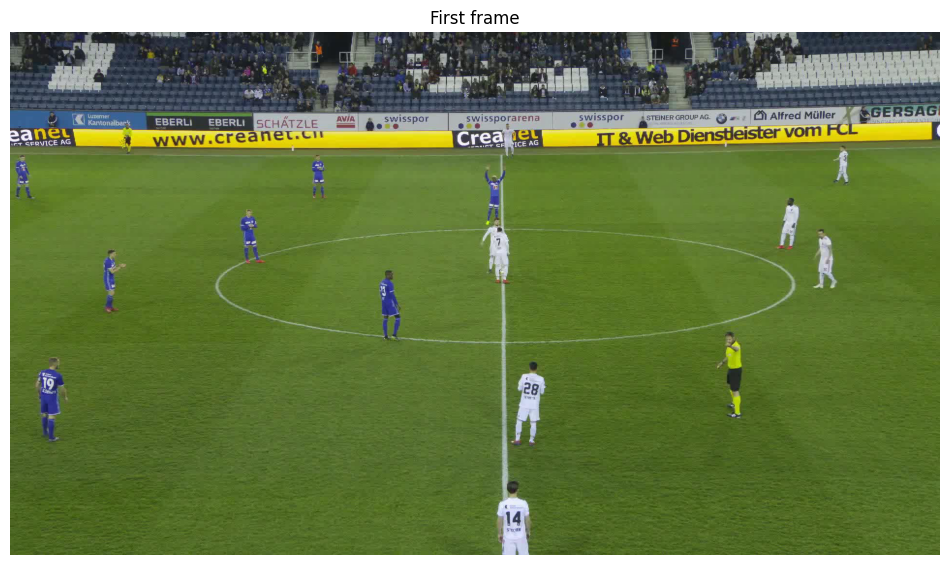

In [9]:
cap = cv2.VideoCapture(str(VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"{VIDEO.name}: {n} frames, {fps:.0f} fps, {w}x{h}, {n/fps:.1f} s")
ok, frame = cap.read()
cap.release()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title("First frame")
plt.show()

persons, balls, best ball conf: (18, 0, nan)


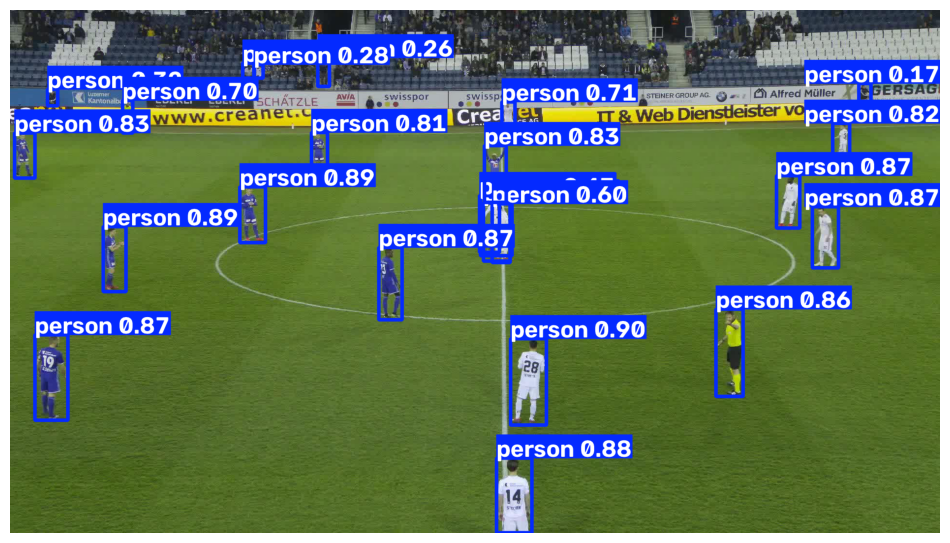

In [10]:
model = YOLO("yolo11m.pt")               # downloads the weights on first run
PERSON, BALL = 0, 32                     # COCO class ids
PERSON_CONF, BALL_CONF = 0.30, 0.10      # thresholds used when counting

def detect(frame):
    return model.predict(frame, imgsz=1280, conf=0.10,
                         classes=[PERSON, BALL], device=DEVICE, verbose=False)[0]

def count(res):
    cls = res.boxes.cls.cpu().numpy()
    conf = res.boxes.conf.cpu().numpy()
    persons = int(((cls == PERSON) & (conf >= PERSON_CONF)).sum())
    balls = int(((cls == BALL) & (conf >= BALL_CONF)).sum())
    ball_conf = conf[cls == BALL].max() if (cls == BALL).any() else np.nan
    return persons, balls, ball_conf

res = detect(frame)
print("persons, balls, best ball conf:", count(res))

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.savefig(OUT / "first_frame_detections.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
MAX_FRAMES = 150      # first run: about 6 seconds. Set to None for the whole clip

rows = []
cap = cv2.VideoCapture(str(VIDEO))
writer = cv2.VideoWriter(str(OUT / f"{VIDEO.stem}_baseline.mp4"),
                         cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
i = 0
raw = []
while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES and i >= MAX_FRAMES):
        break
    res = detect(frame)
    b = res.boxes
    for c, p, xy in zip(b.cls.cpu().numpy(), b.conf.cpu().numpy(), b.xyxy.cpu().numpy()):
        raw.append(dict(frame=i, cls=int(c), conf=float(p),
                        x1=xy[0], y1=xy[1], x2=xy[2], y2=xy[3]))
    persons, balls, ball_conf = count(res)
    rows.append(dict(frame=i, persons=persons, balls=balls, ball_conf=ball_conf))
    writer.write(res.plot())
    i += 1
cap.release(); writer.release()

det = pd.DataFrame(rows)
det.to_csv(OUT / f"{VIDEO.stem}_baseline_counts.csv", index=False)
print(len(det), "frames processed")

150 frames processed


In [7]:
raw = pd.DataFrame(raw)
print(raw.shape)
raw.head()
n_frames = len(det)
persons = raw[raw.cls == PERSON]
ball = raw[raw.cls == BALL]

print("PLAYERS / PERSONS")
for t in [0.3, 0.5, 0.7]:
    per_frame = persons[persons.conf >= t].groupby("frame").size().reindex(range(n_frames), fill_value=0)
    print(f"  conf >= {t}: median {per_frame.median():.0f} per frame (min {per_frame.min()}, max {per_frame.max()})")

print("BALL")
for t in [0.10, 0.25, 0.5]:
    pct = ball[ball.conf >= t].frame.nunique() / n_frames
    print(f"  conf >= {t}: found in {pct:.0%} of frames")

miss = (det.balls == 0).astype(int)
longest = miss.groupby((miss != miss.shift()).cumsum()).sum().max()
print(f"Longest stretch with no ball: {longest} frames ({longest / fps:.1f} s)")

shown = persons[persons.conf >= 0.3]
top = ((shown.y2 < 0.25 * h).sum() / len(shown))
print(f"Rough share of person boxes in the top quarter of the frame (likely stands): {top:.0%}")

(3400, 7)
PLAYERS / PERSONS
  conf >= 0.3: median 17 per frame (min 17, max 19)
  conf >= 0.5: median 17 per frame (min 16, max 17)
  conf >= 0.7: median 16 per frame (min 12, max 17)
BALL
  conf >= 0.1: found in 9% of frames
  conf >= 0.25: found in 1% of frames
  conf >= 0.5: found in 0% of frames
Longest stretch with no ball: 86 frames (3.4 s)
Rough share of person boxes in the top quarter of the frame (likely stands): 12%


In [13]:
DS = PROJECT / "data" / "detection"

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0

def load_gt(lbl, W, H, class_ids):
    boxes = []
    for line in lbl.read_text().splitlines():
        p = line.split()
        if len(p) >= 5 and int(p[0]) in class_ids:
            cx, cy, bw, bh = (float(v) for v in p[1:5])
            boxes.append([(cx-bw/2)*W, (cy-bh/2)*H, (cx+bw/2)*W, (cy+bh/2)*H])
    return boxes

ball_hit = ball_total = player_hit = player_total = 0
for split in ["valid", "test"]:
    for img_path in sorted((DS / split / "images").glob("*")):
        lbl = DS / split / "labels" / (img_path.stem + ".txt")
        if not lbl.exists():
            continue
        img = cv2.imread(str(img_path))
        H, W = img.shape[:2]
        res = detect(img)
        cls = res.boxes.cls.cpu().numpy()
        conf = res.boxes.conf.cpu().numpy()
        xyxy = res.boxes.xyxy.cpu().numpy()
        ball_preds = xyxy[(cls == BALL) & (conf >= BALL_CONF)]
        person_preds = xyxy[(cls == PERSON) & (conf >= PERSON_CONF)]

        for g in load_gt(lbl, W, H, {0}):          # dataset class 0 = Ball
            ball_total += 1
            ball_hit += any(iou(g, p) >= 0.3 for p in ball_preds)
        for g in load_gt(lbl, W, H, {1, 2}):       # dataset 1 = Player, 2 = Ref
            player_total += 1
            player_hit += any(iou(g, p) >= 0.3 for p in person_preds)

print(f"Ball:    found {ball_hit} of {ball_total} ({ball_hit/ball_total:.0%})")
print(f"Players and refs: found {player_hit} of {player_total} ({player_hit/player_total:.0%})")

Ball:    found 31 of 40 (78%)
Players and refs: found 602 of 607 (99%)


In [14]:
ball_hit = ball_total = player_hit = player_total = 0
ball_fp = person_fp = 0

for split in ["valid", "test"]:
    for img_path in sorted((DS / split / "images").glob("*")):
        lbl = DS / split / "labels" / (img_path.stem + ".txt")
        if not lbl.exists():
            continue
        img = cv2.imread(str(img_path))
        H, W = img.shape[:2]
        res = detect(img)
        cls = res.boxes.cls.cpu().numpy()
        conf = res.boxes.conf.cpu().numpy()
        xyxy = res.boxes.xyxy.cpu().numpy()
        ball_preds = xyxy[(cls == BALL) & (conf >= BALL_CONF)]
        person_preds = xyxy[(cls == PERSON) & (conf >= PERSON_CONF)]
        gt_ball = load_gt(lbl, W, H, {0})
        gt_person = load_gt(lbl, W, H, {1, 2})

        ball_total += len(gt_ball)
        player_total += len(gt_person)
        ball_hit += sum(any(iou(g, p) >= 0.3 for p in ball_preds) for g in gt_ball)
        player_hit += sum(any(iou(g, p) >= 0.3 for p in person_preds) for g in gt_person)
        ball_fp += sum(not any(iou(g, p) >= 0.3 for g in gt_ball) for p in ball_preds)
        person_fp += sum(not any(iou(g, p) >= 0.3 for g in gt_person) for p in person_preds)

print(f"Ball:    found {ball_hit} of {ball_total} ({ball_hit/ball_total:.0%}), extra boxes: {ball_fp}")
print(f"Players and refs: found {player_hit} of {player_total} ({player_hit/player_total:.0%}), extra boxes: {person_fp}")

Ball:    found 31 of 40 (78%), extra boxes: 21
Players and refs: found 602 of 607 (99%), extra boxes: 153


In [15]:
baseline = pd.DataFrame([dict(
    model="yolo11m (pretrained)",
    ball_found=ball_hit, ball_total=ball_total, ball_extra=ball_fp,
    person_found=player_hit, person_total=player_total, person_extra=person_fp,
)])
baseline.to_csv(OUT / "baseline_metrics.csv", index=False)
baseline

,model,ball_found,ball_total,ball_extra,person_found,person_total,person_extra
0,yolo11m (pretrained),31,40,21,602,607,153


In [16]:
saved = 0
for split in ["valid", "test"]:
    for img_path in sorted((DS / split / "images").glob("*")):
        lbl = DS / split / "labels" / (img_path.stem + ".txt")
        if not lbl.exists() or saved >= 6:
            continue
        img = cv2.imread(str(img_path)); H, W = img.shape[:2]
        res = detect(img)
        cls = res.boxes.cls.cpu().numpy(); conf = res.boxes.conf.cpu().numpy()
        xyxy = res.boxes.xyxy.cpu().numpy()
        preds = xyxy[(cls == PERSON) & (conf >= PERSON_CONF)]
        gts = load_gt(lbl, W, H, {1, 2})
        extras = [p for p in preds if not any(iou(g, p) >= 0.3 for g in gts)]
        if len(extras) >= 3:
            for g in gts:
                cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 0), 3)
            for p in extras:
                cv2.rectangle(img, (int(p[0]), int(p[1])), (int(p[2]), int(p[3])), (0, 0, 255), 3)
            cv2.imwrite(str(OUT / f"extra_boxes_{saved}.jpg"), img)
            saved += 1
print("saved", saved)

saved 6


## Findings
Test: pretrained yolo11m at 1280 px on the 47 labeled images in valid + test. A detection counts as
"found" if it overlaps a labeled box (IoU >= 0.3). Confidence cutoffs: ball 0.10, person 0.30.
- Found 31 of 40 balls (78%) and 602 of 607 players and referees (99%).
- Extra boxes with no matching label: 21 for the ball and 153 for people.
  Approximate precision (found / (found + extra)): ball about 60%, people about 80%.
- The extra person boxes are on spectators/staff in the sample images checked: yes / partly / no.
- Video check (one 6 s clip, filmed before kickoff, so no ball in play): all on-pitch players and the
  referee detected, plus 3-11 off-pitch people per frame (boxes drawn at conf >= 0.10).
- Referees and goalkeepers are not separated from players (single "person" class).
- Goal for fine-tuning: keep recall, cut the extra boxes, separate the referee.